# Benchmark des modèles — XGBoost à t+15 minutes

Projet : **Traffic Prediction & Adaptive Signal Control Agent — PEMS08**.

La cible principale est **target_occupy_t15**, l'occupation du même capteur trois timesteps dans le futur. Nous entraînons uniquement sur **train**, choisissons les hyperparamètres et le nombre d'arbres sur **validation**, puis évaluons une seule configuration sur **test**.

Ce benchmark prédit une valeur continue d'occupation, pas une classe de congestion. Les prévisions sont produites à chaque t, une fois les mesures courantes reçues.

Dépendances du noyau : pandas, numpy, matplotlib, scikit-learn et XGBoost 3.2 ou ultérieur. Si nécessaire, installer XGBoost dans le noyau avec **%pip install xgboost-cpu** avant d'exécuter ce notebook.


In [1]:
# Importer les outils de mesure, de manipulation, de visualisation et de modélisation.
from pathlib import Path
from time import perf_counter
import gc
import json
import os
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fixer les graines et limiter le parallélisme pour un benchmark reproductible.
RANDOM_STATE = 42
N_JOBS = min(4, os.cpu_count() or 1)
print("Versions :", "XGBoost", xgboost.__version__, "| scikit-learn", sklearn.__version__)
print("CPU :", platform.processor(), "| threads utilisés :", N_JOBS)


Versions : XGBoost 3.2.0 | scikit-learn 1.8.0
CPU : AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD | threads utilisés : 4


## Charger la préparation précédente

Le notebook 02 ne sauvegarde pas encore les ensembles sur disque. Nous le réexécutons avec la commande IPython **run** pour récupérer directement **train**, **validation** et **test**, sans dupliquer la logique de préparation.

Cela conserve le découpage temporel 70/15/15 commun aux 170 capteurs et la purge des cibles traversant les frontières. Ce chargement reconstruit les données et peut prendre quelques instants ; son temps est exclu du temps d'entraînement du modèle.


In [2]:
# Localiser le notebook 02 depuis notebooks ou depuis la racine du projet.
chemin_preparation = Path("02_feature_engineering.ipynb")
if not chemin_preparation.exists():
    chemin_preparation = Path("notebooks/02_feature_engineering.ipynb")
assert chemin_preparation.exists(), "Le notebook de préparation est introuvable."

# Réexécuter la préparation validée et récupérer ses variables dans ce noyau.
get_ipython().run_line_magic("run", str(chemin_preparation))

# Vérifier à nouveau que les cibles de train et validation restent dans leur période.
assert train["timestep"].max() + horizon < validation["timestep"].min()
assert validation["timestep"].max() + horizon < test["timestep"].min()
assert horizon == 3

# Libérer les grands tableaux intermédiaires ; conserver les trois ensembles finaux.
del df, df_features, ensembles, exemples, ensemble
gc.collect()
print("Shapes :", "train", train.shape, "| validation", validation.shape, "| test", test.shape)


Shape du dataset source : (3035520, 5)
Nombre de capteurs : 170
Shape avant nettoyage : (3035520, 37)
Shape après nettoyage : (3032970, 37)
Lignes supprimées : 2550
NaN restants par colonne :
timestep                  0
location                  0
flow                      0
occupy                    0
speed                     0
day_index                 0
slot_in_day               0
hour                      0
minute                    0
time_label                0
flow_lag_1                0
flow_lag_2                0
flow_lag_3                0
flow_lag_6                0
flow_lag_12               0
speed_lag_1               0
speed_lag_2               0
speed_lag_3               0
speed_lag_6               0
speed_lag_12              0
occupy_lag_1              0
occupy_lag_2              0
occupy_lag_3              0
occupy_lag_6              0
occupy_lag_12             0
flow_rolling_mean_3       0
flow_rolling_mean_6       0
flow_rolling_mean_12      0
speed_rolling_mean_3    

## Choisir les features sans information future

Nous conservons les trois mesures courantes, les **15 lags**, les **9 moyennes glissantes**, les variables temporelles numériques et l'identifiant du capteur.

**location** est traité comme une catégorie, sans supposer un ordre numérique entre capteurs. Les catégories sont définies sur train seulement. **time_label** sert à l'affichage et **timestep** est redondant avec day_index et slot_in_day : ils sont exclus. Toutes les colonnes **target_*** sont exclues des features.

Les moyennes glissantes ont déjà été décalées vers le passé. Aucune normalisation n'est nécessaire pour ce modèle d'arbres.


In [3]:
# Énumérer explicitement les colonnes autorisées pour éviter d'inclure une cible future.
target_column = "target_occupy_t15"
feature_columns = (
    ["location", "day_index", "slot_in_day", "hour", "minute", "flow", "speed", "occupy"]
    + colonnes_lags
    + colonnes_rolling
)
assert not any(colonne.startswith("target_") for colonne in feature_columns)
assert len(feature_columns) == len(set(feature_columns))

# Définir les catégories à partir de train, puis appliquer le même type aux autres ensembles.
type_capteur = pd.CategoricalDtype(categories=sorted(train["location"].unique()))

# Préparer une matrice de features sans ajuster de transformation sur validation ou test.
def preparer_features(ensemble):
    # Vérifier qu'aucun capteur inconnu ne devient silencieusement une valeur manquante.
    assert ensemble["location"].isin(type_capteur.categories).all()
    X = ensemble[feature_columns].copy()
    X["location"] = X["location"].astype(type_capteur)
    # Le float32 limite la mémoire sans modifier les mesures source conservées dans les ensembles.
    colonnes_numeriques = [colonne for colonne in feature_columns if colonne != "location"]
    X[colonnes_numeriques] = X[colonnes_numeriques].astype("float32")
    assert not X.isna().any().any()
    return X

# Préparer uniquement train et validation avant la sélection des hyperparamètres.
X_train = preparer_features(train)
X_validation = preparer_features(validation)
y_train = train[target_column]
y_validation = validation[target_column]
print("Nombre de features :", len(feature_columns))
print("Features :", feature_columns)


Nombre de features : 32
Features : ['location', 'day_index', 'slot_in_day', 'hour', 'minute', 'flow', 'speed', 'occupy', 'flow_lag_1', 'flow_lag_2', 'flow_lag_3', 'flow_lag_6', 'flow_lag_12', 'speed_lag_1', 'speed_lag_2', 'speed_lag_3', 'speed_lag_6', 'speed_lag_12', 'occupy_lag_1', 'occupy_lag_2', 'occupy_lag_3', 'occupy_lag_6', 'occupy_lag_12', 'flow_rolling_mean_3', 'flow_rolling_mean_6', 'flow_rolling_mean_12', 'speed_rolling_mean_3', 'speed_rolling_mean_6', 'speed_rolling_mean_12', 'occupy_rolling_mean_3', 'occupy_rolling_mean_6', 'occupy_rolling_mean_12']


## Sélection des hyperparamètres sur validation

Nous comparons **trois configurations fixées à l'avance**, faisant varier la profondeur, le taux d'apprentissage et la régularisation par min_child_weight. La recherche reste volontairement limitée.

Le critère de sélection est la **RMSE de validation**. L'arrêt anticipé après 25 itérations sans amélioration choisit le nombre utile d'arbres, sans consulter test. Le meilleur modèle est conservé tel quel, entraîné uniquement sur train.

Le temps de chaque entraînement inclut les évaluations internes sur validation. Le temps total de recherche inclut aussi la comparaison des candidats. Les options utilisées suivent la [documentation officielle XGBoost](https://xgboost.readthedocs.io/en/release_3.2.0/python/python_api.html) et sa [gestion des catégories](https://xgboost.readthedocs.io/en/release_3.2.0/tutorials/categorical.html).


In [5]:
# Définir une petite liste de configurations plutôt qu'une recherche coûteuse.
configurations = [
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.10, "min_child_weight": 5},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.05, "min_child_weight": 5},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.10, "min_child_weight": 10},
]

# Partager les paramètres fixes, notamment le calcul CPU par histogrammes.
parametres_communs = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "tree_method": "hist",
    "device": "cpu",
    "enable_categorical": True,
    "max_bin": 128,
    "subsample": 0.8,
    "colsample_bytree": 0.9,
    "reg_lambda": 1.0,
    "early_stopping_rounds": 25,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS,
}

# Initialiser le suivi des essais sans toucher à l'ensemble test.
essais = []
best_model = None
meilleure_rmse = float("inf")
debut_recherche = perf_counter()

for numero, configuration in enumerate(configurations, start=1):
    # Entraîner ce candidat sur train, avec arrêt anticipé sur validation seulement.
    modele = XGBRegressor(**parametres_communs, **configuration)
    debut_entrainement = perf_counter()
    modele.fit(X_train, y_train, eval_set=[(X_validation, y_validation)], verbose=False)
    temps_entrainement = perf_counter() - debut_entrainement

    # predict utilise automatiquement la meilleure itération de l'arrêt anticipé.
    prediction_validation = modele.predict(X_validation)
    rmse_validation = float(np.sqrt(mean_squared_error(y_validation, prediction_validation)))
    essais.append({
        "essai": numero,
        **configuration,
        "best_n_estimators": modele.best_iteration + 1,
        "validation_MAE": mean_absolute_error(y_validation, prediction_validation),
        "validation_RMSE": rmse_validation,
        "validation_R2": r2_score(y_validation, prediction_validation),
        "training_time_s": temps_entrainement,
    })
    print(f"Essai {numero} : RMSE validation = {rmse_validation:.6f}, entraînement = {temps_entrainement:.2f} s", flush=True)

    # Conserver uniquement le modèle choisi par la RMSE de validation.
    if rmse_validation < meilleure_rmse:
        meilleure_rmse = rmse_validation
        best_model = modele
        best_configuration = configuration.copy()
        best_training_time_s = temps_entrainement

# Afficher tous les essais pour rendre le choix du modèle vérifiable.
tuning_time_s = perf_counter() - debut_recherche
validation_results = pd.DataFrame(essais).sort_values("validation_RMSE").reset_index(drop=True)
print("Configuration retenue :", best_configuration)
print("Nombre d'arbres retenus :", best_model.best_iteration + 1)
validation_results


Essai 1 : RMSE validation = 0.015192, entraînement = 35.95 s
Essai 2 : RMSE validation = 0.015204, entraînement = 43.23 s
Essai 3 : RMSE validation = 0.015159, entraînement = 36.87 s
Configuration retenue : {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 10}
Nombre d'arbres retenus : 133


,essai,n_estimators,max_depth,learning_rate,min_child_weight,best_n_estimators,validation_MAE,validation_RMSE,validation_R2,training_time_s
0,3,300,6,0.10,10,133,0.006041,0.015159,0.892640,36.874327
1,1,200,4,0.10,5,200,0.006164,0.015192,0.892173,35.951896
2,2,300,6,0.05,5,167,0.006037,0.015204,0.891995,43.225575


## Évaluation finale sur test

Le choix est maintenant figé. Nous calculons **MAE**, **RMSE** et **R²** sur toutes les observations de test, dans l'échelle originale de occupy. Plus MAE et RMSE sont faibles, mieux c'est ; R² peut être négatif si le modèle fait moins bien qu'une prédiction constante par la moyenne.

Le temps d'inférence mesure une prédiction par lot sur tout test, après un petit échauffement. Il exclut le chargement et la préparation des features. Le temps moyen par observation est un débit de traitement par lot, pas une latence de requête individuelle.


In [ ]:
# Préparer test seulement après la sélection définitive du modèle.
X_test = preparer_features(test)
y_test = test[target_column]

# Effectuer un petit échauffement pour ne pas mesurer l'initialisation seule.
_ = best_model.predict(X_test.iloc[:1000])

# Mesurer une prédiction complète sur l'ensemble test, sans sous-échantillonnage.
debut_inference = perf_counter()
y_pred = best_model.predict(X_test)
inference_time_s = perf_counter() - debut_inference

# Évaluer les prédictions brutes, sans écrêtage ni ajustement à partir de test.
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
test_r2 = r2_score(y_test, y_pred)
assert len(y_pred) == len(y_test) and np.isfinite(y_pred).all()

# Regrouper les résultats dans un schéma extensible aux prochains modèles.
resultat_xgboost = {
    "model": "XGBoost Regressor",
    "target": target_column,
    "horizon_minutes": 15,
    "MAE": test_mae,
    "RMSE": test_rmse,
    "R2": test_r2,
    "training_time_s": best_training_time_s,
    "tuning_time_s": tuning_time_s,
    "inference_time_s": inference_time_s,
    "inference_us_per_row": inference_time_s / len(test) * 1_000_000,
    "validation_RMSE": meilleure_rmse,
    "n_train": len(train),
    "n_validation": len(validation),
    "n_test": len(test),
    "n_features": len(feature_columns),
    "best_n_estimators": best_model.best_iteration + 1,
    "xgboost_version": xgboost.__version__,
    "n_jobs": N_JOBS,
    "hyperparameters": json.dumps(best_configuration, sort_keys=True),
}

# Préserver les autres modèles si cette cellule est rejouée dans le même noyau.
if "benchmark_results" not in globals():
    benchmark_results = pd.DataFrame([resultat_xgboost])
else:
    meme_modele = (
        benchmark_results["model"].eq(resultat_xgboost["model"])
        & benchmark_results["target"].eq(target_column)
        & benchmark_results["horizon_minutes"].eq(15)
    )
    benchmark_results = pd.concat(
        [benchmark_results.loc[~meme_modele], pd.DataFrame([resultat_xgboost])],
        ignore_index=True
    )
benchmark_results


,model,target,horizon_minutes,MAE,RMSE,R2,training_time_s,tuning_time_s,inference_time_s,inference_us_per_row,validation_RMSE,n_train,n_validation,n_test,n_features,best_n_estimators,xgboost_version,n_jobs,hyperparameters
0,XGBoost Regressor,target_occupy_t15,15,0.006494,0.01644,0.890765,30.325994,101.416394,0.465378,1.022606,0.015159,2122450,454410,455090,32,133,3.2.0,4,"{""learning_rate"": 0.1, ""max_depth"": 6, ""min_ch..."


## Valeurs réelles et prédites

Le nuage utilise un échantillon reproductible pour rester lisible ; les métriques précédentes utilisent bien **tout test**. La diagonale représente une prédiction parfaite.


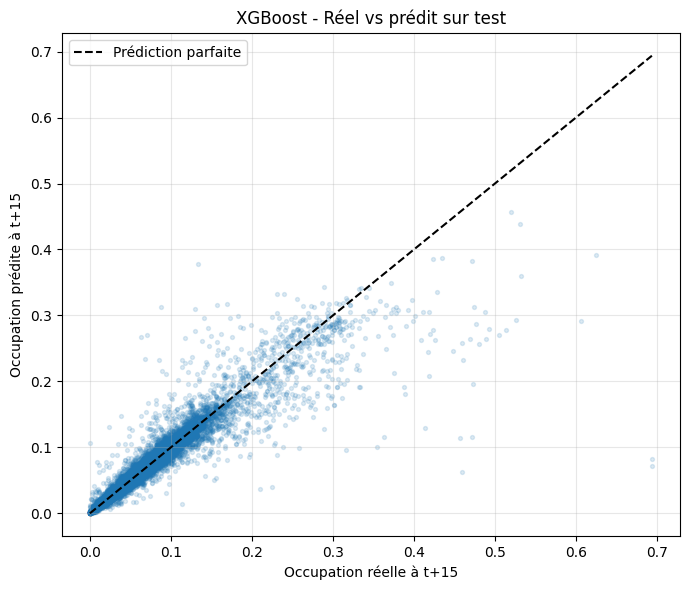

In [ ]:
# Échantillonner uniquement pour le graphique, jamais pour le calcul des métriques.
generateur = np.random.default_rng(RANDOM_STATE)
positions = generateur.choice(len(y_test), size=min(20000, len(y_test)), replace=False)
valeurs_reelles = y_test.to_numpy()
minimum = min(valeurs_reelles[positions].min(), y_pred[positions].min())
maximum = max(valeurs_reelles[positions].max(), y_pred[positions].max())

# Comparer les valeurs réelles à t+15 et les prédictions correspondantes.
plt.figure(figsize=(7, 6))
plt.scatter(valeurs_reelles[positions], y_pred[positions], s=8, alpha=0.15)
plt.plot([minimum, maximum], [minimum, maximum], "--", color="black", label="Prédiction parfaite")
plt.xlabel("Occupation réelle à t+15")
plt.ylabel("Occupation prédite à t+15")
plt.title("XGBoost - Réel vs prédit sur test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Analyse des erreurs

Nous définissons l'erreur comme **prédiction − valeur réelle** : une erreur positive correspond à une surestimation. L'histogramme décrit tout test ; le second graphique aide à repérer un biais selon le niveau d'occupation. Ces diagnostics ne servent pas à modifier les hyperparamètres après évaluation.


Erreur moyenne signée : -0.00018720243072049332


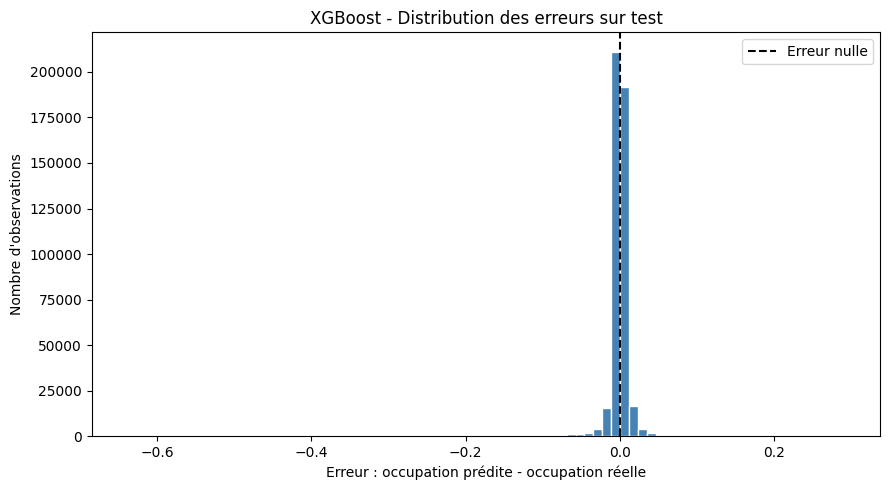

In [ ]:
# Calculer les erreurs sur tout test avec une convention de signe explicite.
erreurs = y_pred - valeurs_reelles
print("Erreur moyenne signée :", erreurs.mean())

# Visualiser la distribution des erreurs ; zéro représente une prédiction exacte.
plt.figure(figsize=(9, 5))
plt.hist(erreurs, bins=80, color="steelblue", edgecolor="white")
plt.axvline(0, color="black", linestyle="--", label="Erreur nulle")
plt.xlabel("Erreur : occupation prédite - occupation réelle")
plt.ylabel("Nombre d'observations")
plt.title("XGBoost - Distribution des erreurs sur test")
plt.legend()
plt.tight_layout()
plt.show()


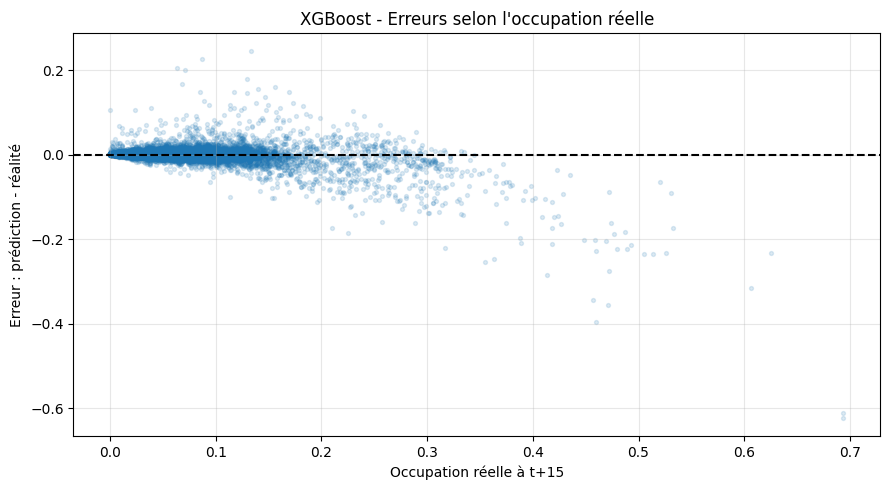

In [ ]:
# Vérifier si l'erreur change avec le niveau réel d'occupation.
plt.figure(figsize=(9, 5))
plt.scatter(valeurs_reelles[positions], erreurs[positions], s=8, alpha=0.15)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Occupation réelle à t+15")
plt.ylabel("Erreur : prédiction - réalité")
plt.title("XGBoost - Erreurs selon l'occupation réelle")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Importance des features

Le **gain** mesure l'amélioration moyenne du critère apportée par les divisions utilisant une feature. Nous calculons cette importance sur les arbres effectivement retenus par l'arrêt anticipé, puis la normalisons.

Cette importance est descriptive, pas causale. Les lags et moyennes glissantes sont corrélés entre eux : leur contribution peut être répartie entre plusieurs colonnes.


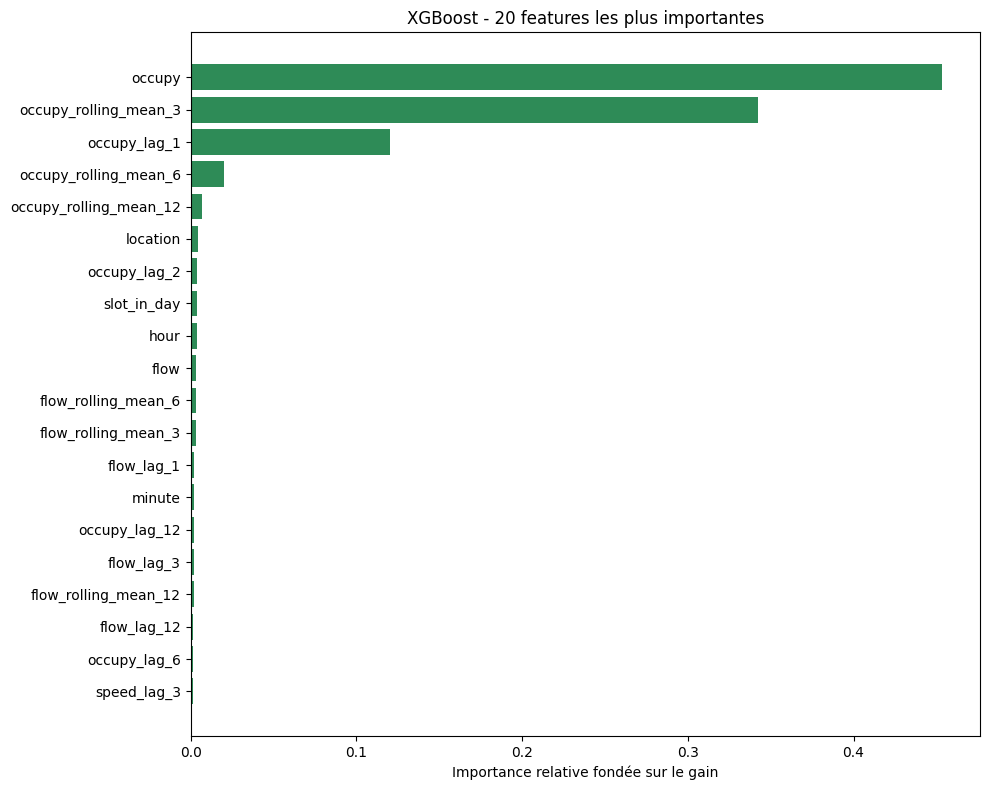

,feature,gain,importance
7,occupy,16.879227,0.453609
29,occupy_rolling_mean_3,12.749084,0.342617
18,occupy_lag_1,4.485931,0.120554
30,occupy_rolling_mean_6,0.747035,0.020076
31,occupy_rolling_mean_12,0.262247,0.007048
0,location,0.175209,0.004709
19,occupy_lag_2,0.149514,0.004018
2,slot_in_day,0.148176,0.003982
3,hour,0.147946,0.003976
5,flow,0.126286,0.003394


In [ ]:
# Limiter le calcul d'importance aux arbres réellement utilisés pour prédire.
booster_retenu = best_model.get_booster()[:best_model.best_iteration + 1]
gains = booster_retenu.get_score(importance_type="gain")
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "gain": [gains.get(colonne, 0.0) for colonne in feature_columns],
})
total_gain = feature_importance["gain"].sum()
feature_importance["importance"] = (
    feature_importance["gain"] / total_gain if total_gain > 0 else 0.0
)
feature_importance = feature_importance.sort_values("importance", ascending=False)

# Afficher les vingt variables les plus importantes sur un graphique séparé.
top_features = feature_importance.head(20).sort_values("importance")
plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"], color="seagreen")
plt.xlabel("Importance relative fondée sur le gain")
plt.title("XGBoost - 20 features les plus importantes")
plt.tight_layout()
plt.show()
feature_importance.head(20)


## Conserver les résultats pour les prochains benchmarks

**benchmark_results** contient les métriques et temps du modèle sélectionné. LSTM, TCN et Transformer pourront être ajoutés avec le même schéma et les mêmes périodes de test. Les comparaisons de temps devront utiliser des conditions matérielles et des tailles de lots comparables.

Nous sauvegardons aussi les résultats, les essais et les importances en CSV pour pouvoir les consulter après fermeture du noyau.


In [ ]:
# Enregistrer les tableaux de résultats dans un dossier du projet.
racine_projet = chemin_preparation.resolve().parent.parent
dossier_resultats = racine_projet / "results" / "model_benchmark"
dossier_resultats.mkdir(parents=True, exist_ok=True)
benchmark_results.to_csv(dossier_resultats / "benchmark_results.csv", index=False)
validation_results.to_csv(dossier_resultats / "xgboost_validation_results.csv", index=False)
feature_importance.to_csv(dossier_resultats / "xgboost_feature_importance.csv", index=False)

# Afficher le bilan final sans réentraîner le modèle ni consulter de nouveau les cibles pour le régler.
print(f"Test : MAE={test_mae:.6f}, RMSE={test_rmse:.6f}, R²={test_r2:.4f}")
print(f"Entraînement du modèle retenu : {best_training_time_s:.2f} s")
print(f"Recherche complète : {tuning_time_s:.2f} s")
print(f"Inférence sur {len(test):,} lignes : {inference_time_s:.3f} s")
print("Résultats enregistrés dans :", dossier_resultats)


Test : MAE=0.006494, RMSE=0.016440, R²=0.8908
Entraînement du modèle retenu : 30.33 s
Recherche complète : 101.42 s
Inférence sur 455,090 lignes : 0.465 s
Résultats enregistrés dans : C:\Users\User\GoFlow\results\model_benchmark


## Benchmark LSTM — Séquences de 12 observations

Le LSTM reçoit uniquement **flow, speed et occupy**, sous forme de séquences allant de **t−11 à t inclus**, et prédit **target_occupy_t15**, soit occupy à **t+3**. Les 12 observations représentent 12 intervalles de 5 minutes ; leurs horodatages extrêmes sont séparés de 55 minutes.

Nous conservons **exactement les lignes et les cibles des ensembles train, validation et test du benchmark XGBoost**. L'historique est récupéré dans le CSV source, notamment au début de chaque période : ces observations passées sont disponibles à t. Aucune séquence ne traverse une frontière entre capteurs.

Les lignes de bord exclues du split peuvent servir d'historique passé, mais ne sont pas réintroduites comme exemples d'entraînement. Le modèle ne conserve pas d'état caché entre deux séquences indépendantes.


In [ ]:
# Importer PyTorch pour construire un réseau récurrent simple.
import copy
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler

# Fixer les graines et le nombre de threads pour faciliter la reproduction.
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.set_num_threads(N_JOBS)

# Utiliser le GPU s'il est disponible, sinon le CPU.
lstm_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if lstm_device.type == "cuda":
    torch.cuda.manual_seed_all(RANDOM_STATE)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Définir les entrées et la longueur des séquences, sans reprendre les lags de XGBoost.
lstm_features = ["flow", "speed", "occupy"]
lstm_sequence_length = 12
print("PyTorch :", torch.__version__, "| matériel :", lstm_device)


PyTorch : 2.11.0+cpu | matériel : cpu


### Normalisation ajustée uniquement sur train

Nous standardisons chaque variable par sa moyenne et son écart-type calculés **uniquement sur les lignes de train**, sans pondérer plusieurs fois une mesure présente dans plusieurs fenêtres.

La cible est également standardisée avec un second transformateur ajusté sur les **cibles de train seulement**, pour faciliter l'optimisation. Les prédictions seront reconverties dans l'échelle originale avant toutes les métriques. Validation et test ne participent à aucun ajustement.


In [ ]:
# Ajuster les deux normalisations exclusivement sur train.
lstm_scaler_X = StandardScaler()
lstm_scaler_y = StandardScaler()
lstm_scaler_X.fit(train[lstm_features])
lstm_scaler_y.fit(train[["target_occupy_t15"]])

# Recharger uniquement les colonnes nécessaires pour retrouver tout l'historique passé.
chemin_source_lstm = chemin_preparation.resolve().parent.parent / "data" / "raw" / "traffic_dataset.csv"
source_lstm = pd.read_csv(
    chemin_source_lstm, usecols=["location", "timestep"] + lstm_features
).sort_values(["location", "timestep"]).reset_index(drop=True)

# Vérifier l'unicité et la continuité temporelle avant toute extraction de fenêtre.
assert not source_lstm.duplicated(["location", "timestep"]).any()
assert source_lstm.groupby("location")["timestep"].diff().dropna().eq(1).all()
assert not source_lstm.isna().any().any()

# Transformer l'historique avec les statistiques de train, sans nouvel ajustement.
# Conserver un seul tableau de mesures ; les fenêtres seront assemblées par lots.
lstm_base = torch.from_numpy(
    lstm_scaler_X.transform(source_lstm[lstm_features]).astype("float32")
)
lstm_source_index = pd.MultiIndex.from_frame(source_lstm[["location", "timestep"]])
lstm_offsets = torch.arange(-lstm_sequence_length + 1, 1)

# Afficher les statistiques utilisées pour rendre la normalisation vérifiable.
lstm_normalisation = pd.DataFrame({
    "feature": lstm_features,
    "moyenne_train": lstm_scaler_X.mean_,
    "ecart_type_train": lstm_scaler_X.scale_,
})
lstm_normalisation


,feature,moyenne_train,ecart_type_train
0,flow,230.335795,145.879290
1,speed,63.779774,6.560733
2,occupy,0.064637,0.044949


In [ ]:
# Associer chaque exemple à sa position de fin dans l'historique trié.
def indexer_sequences_lstm(ensemble):
    # Retrouver les mêmes couples location-timestep que dans le benchmark précédent.
    cles = pd.MultiIndex.from_frame(ensemble[["location", "timestep"]])
    fins = lstm_source_index.get_indexer(cles)
    debuts = fins - lstm_sequence_length + 1
    assert (debuts >= 0).all(), "Une séquence ne dispose pas de tout son historique."

    # La source est triée et continue par capteur : ces contrôles garantissent
    # que tous les points de chaque fenêtre appartiennent au même capteur.
    locations = source_lstm["location"].to_numpy()
    timesteps = source_lstm["timestep"].to_numpy()
    assert np.array_equal(locations[debuts], ensemble["location"].to_numpy())
    assert np.array_equal(locations[fins], ensemble["location"].to_numpy())
    assert np.array_equal(timesteps[fins], ensemble["timestep"].to_numpy())
    assert np.all(timesteps[fins] - timesteps[debuts] == lstm_sequence_length - 1)

    # Vérifier la cible exacte à t+3, toujours pour le même capteur.
    positions_cibles = fins + horizon
    assert (positions_cibles < len(source_lstm)).all()
    assert np.array_equal(locations[positions_cibles], locations[fins])
    assert np.all(timesteps[positions_cibles] == timesteps[fins] + horizon)
    np.testing.assert_allclose(
        source_lstm["occupy"].to_numpy()[positions_cibles],
        ensemble["target_occupy_t15"].to_numpy()
    )

    # Normaliser les cibles avec les statistiques déjà ajustées sur train.
    cibles = lstm_scaler_y.transform(ensemble[["target_occupy_t15"]]).ravel()
    return torch.from_numpy(fins.copy()), torch.from_numpy(cibles.astype("float32"))

# Préparer train et validation sans construire des millions de fenêtres en mémoire.
lstm_train_ends, lstm_y_train = indexer_sequences_lstm(train)
lstm_validation_ends, lstm_y_validation = indexer_sequences_lstm(validation)

# Montrer que la première fenêtre possède bien la forme attendue : 12 temps, 3 variables.
premiere_sequence = lstm_base[lstm_train_ends[0] + lstm_offsets]
assert tuple(premiere_sequence.shape) == (12, 3)
print("Séquences train :", len(lstm_train_ends))
print("Séquences validation :", len(lstm_validation_ends))
print("Forme d'une séquence :", tuple(premiere_sequence.shape))


Séquences train : 2122450
Séquences validation : 454410
Forme d'une séquence : (12, 3)


### Architecture et entraînement

Architecture : **une couche LSTM de 16 unités**, suivie d'une sortie linéaire scalaire. La perte est la MSE de la cible standardisée, optimisée avec Adam.

Nous fixons au maximum **15 époques**, avec arrêt anticipé après **3 époques sans amélioration de la RMSE de validation**, puis restaurons les meilleurs poids. Aucun réglage n'utilise test.

Seul l'ordre des exemples de train est mélangé à chaque époque : le split reste chronologique et l'ordre des 12 observations à l'intérieur de chaque séquence est conservé. Les fenêtres sont créées par lots pour limiter la mémoire.

Référence : [documentation officielle de torch.nn.LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).


In [ ]:
# Définir un modèle récurrent compact, avec un nouvel état caché pour chaque séquence.
class TrafficLSTM(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        # batch_first impose la forme : nombre de séquences, temps, variables.
        self.lstm = nn.LSTM(input_size=3, hidden_size=hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, sequences):
        # Ne transmettre aucun état initial réutilisé entre lots ou capteurs.
        _, (hidden, _) = self.lstm(sequences)
        return self.output(hidden[-1]).squeeze(-1)

# Assembler uniquement les fenêtres nécessaires au lot courant.
def lots_lstm(fins, cibles=None, melanger=False, batch_size=2048):
    # Le mélange éventuel porte sur les séquences entières, jamais sur leurs timesteps.
    ordre = torch.randperm(len(fins)) if melanger else torch.arange(len(fins))
    for debut in range(0, len(fins), batch_size):
        positions = ordre[debut:debut + batch_size]
        indices_fenetres = fins[positions, None] + lstm_offsets[None, :]
        X_lot = lstm_base[indices_fenetres].to(lstm_device)
        y_lot = None if cibles is None else cibles[positions].to(lstm_device)
        yield X_lot, y_lot

# Synchroniser le GPU pour que les chronométrages incluent les calculs asynchrones.
def synchroniser_lstm():
    if lstm_device.type == "cuda":
        torch.cuda.synchronize()

# Initialiser un modèle neuf pour rendre la cellule réexécutable.
torch.manual_seed(RANDOM_STATE)
lstm_model = TrafficLSTM(hidden_size=16).to(lstm_device)
lstm_optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
lstm_loss = nn.MSELoss()
lstm_batch_size = 2048
lstm_max_epochs = 15
lstm_patience = 3
print("Nombre de paramètres :", sum(p.numel() for p in lstm_model.parameters()))


Nombre de paramètres : 1361


In [ ]:
# Suivre la validation sans calculer de gradient et sans consulter test.
def rmse_validation_lstm():
    lstm_model.eval()
    somme_erreurs = 0.0
    with torch.inference_mode():
        for X_lot, y_lot in lots_lstm(
            lstm_validation_ends, lstm_y_validation, batch_size=lstm_batch_size
        ):
            predictions = lstm_model(X_lot)
            somme_erreurs += ((predictions - y_lot) ** 2).sum().item()
    # Revenir à l'échelle originale de occupy pour interpréter la RMSE.
    return np.sqrt(somme_erreurs / len(lstm_y_validation)) * lstm_scaler_y.scale_[0]

# Mesurer l'entraînement complet, y compris les évaluations de validation.
lstm_history_rows = []
lstm_best_rmse = float("inf")
lstm_best_state = None
lstm_epochs_without_improvement = 0
synchroniser_lstm()
lstm_training_start = perf_counter()

for epoch in range(1, lstm_max_epochs + 1):
    # Entraîner sur toutes les séquences de train une fois par époque.
    lstm_model.train()
    somme_loss = 0.0
    epoch_start = perf_counter()
    for X_lot, y_lot in lots_lstm(
        lstm_train_ends, lstm_y_train, melanger=True, batch_size=lstm_batch_size
    ):
        lstm_optimizer.zero_grad(set_to_none=True)
        predictions = lstm_model(X_lot)
        loss = lstm_loss(predictions, y_lot)
        loss.backward()
        # Limiter les gradients extrêmes pour stabiliser l'entraînement récurrent.
        nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)
        lstm_optimizer.step()
        somme_loss += loss.item() * len(y_lot)

    # Comparer la validation dans son unité originale et conserver les meilleurs poids.
    validation_rmse = rmse_validation_lstm()
    train_rmse = np.sqrt(somme_loss / len(lstm_y_train)) * lstm_scaler_y.scale_[0]
    assert np.isfinite(validation_rmse), "La perte est devenue non finie."
    if validation_rmse < lstm_best_rmse:
        lstm_best_rmse = validation_rmse
        lstm_best_epoch = epoch
        lstm_best_state = copy.deepcopy(lstm_model.state_dict())
        lstm_epochs_without_improvement = 0
    else:
        lstm_epochs_without_improvement += 1

    # Enregistrer les courbes d'apprentissage et le temps de chaque époque.
    synchroniser_lstm()
    lstm_history_rows.append({
        "epoch": epoch, "train_RMSE": train_rmse,
        "validation_RMSE": validation_rmse,
        "epoch_time_s": perf_counter() - epoch_start,
    })
    print(f"Époque {epoch:02d} : train RMSE={train_rmse:.6f}, validation RMSE={validation_rmse:.6f}", flush=True)
    if lstm_epochs_without_improvement >= lstm_patience:
        print("Arrêt anticipé : la validation ne s'améliore plus.", flush=True)
        break

# Restaurer le modèle choisi sur validation, et non les poids de la dernière époque.
lstm_model.load_state_dict(lstm_best_state)
lstm_model.eval()
synchroniser_lstm()
lstm_training_time_s = perf_counter() - lstm_training_start
lstm_history = pd.DataFrame(lstm_history_rows)
print("Meilleure époque :", lstm_best_epoch)
print(f"Temps total d'entraînement : {lstm_training_time_s:.2f} s")
lstm_history


Époque 01 : train RMSE=0.019189, validation RMSE=0.015882


Époque 02 : train RMSE=0.015214, validation RMSE=0.015635


Époque 03 : train RMSE=0.015126, validation RMSE=0.015509


Époque 04 : train RMSE=0.015073, validation RMSE=0.015431


Époque 05 : train RMSE=0.015030, validation RMSE=0.015425


Époque 06 : train RMSE=0.014996, validation RMSE=0.015394


... (5 outputs left out)

Époque 12 : train RMSE=0.014897, validation RMSE=0.015371


Arrêt anticipé : la validation ne s'améliore plus.


Meilleure époque : 9
Temps total d'entraînement : 174.50 s


,epoch,train_RMSE,validation_RMSE,epoch_time_s
0,1,0.019189,0.015882,14.863577
1,2,0.015214,0.015635,14.284388
2,3,0.015126,0.015509,14.109197
3,4,0.015073,0.015431,14.299745
4,5,0.015030,0.015425,14.170395
5,6,0.014996,0.015394,14.771205
6,7,0.014970,0.015349,14.674470
7,8,0.014953,0.015361,14.625587
8,9,0.014938,0.015310,14.492209
9,10,0.014918,0.015321,15.054690


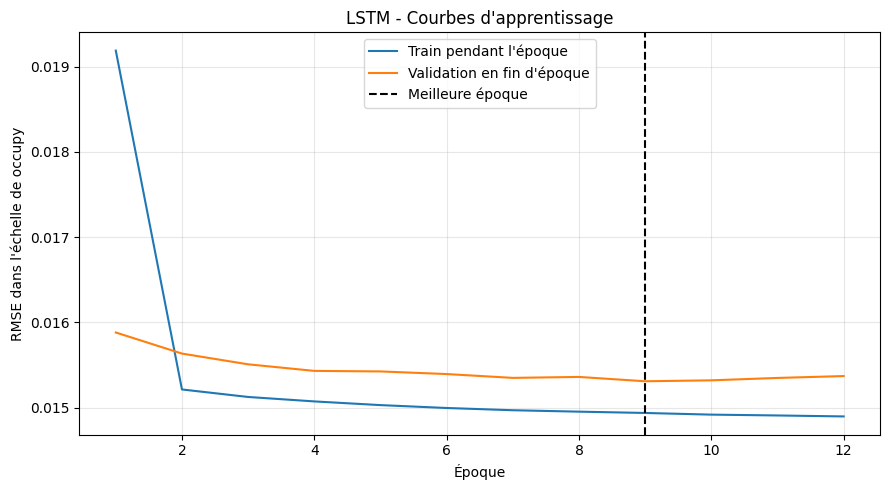

In [ ]:
# Visualiser l'apprentissage sans utiliser les résultats du test pour régler le modèle.
plt.figure(figsize=(9, 5))
plt.plot(lstm_history["epoch"], lstm_history["train_RMSE"], label="Train pendant l'époque")
plt.plot(lstm_history["epoch"], lstm_history["validation_RMSE"], label="Validation en fin d'époque")
plt.axvline(lstm_best_epoch, color="black", linestyle="--", label="Meilleure époque")
plt.xlabel("Époque")
plt.ylabel("RMSE dans l'échelle de occupy")
plt.title("LSTM - Courbes d'apprentissage")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Évaluation sur les mêmes observations de test

Nous utilisons les meilleurs poids sélectionnés sur validation. Les métriques sont calculées sur toutes les lignes de test, dans l'échelle originale, sans écrêtage des prédictions.

Le temps d'inférence est mesuré après échauffement. Il inclut l'assemblage des séquences par lots, les éventuels transferts vers le GPU et la reconversion des prédictions. Le chargement du CSV et l'ajustement des normalisations en sont exclus. Cette mesure par lot n'est pas une latence individuelle ; son périmètre inclut davantage de préparation que celui du XGBoost.


In [ ]:
# Préparer les séquences test seulement après le choix des meilleurs poids.
lstm_test_ends, _ = indexer_sequences_lstm(test)
assert len(lstm_test_ends) == len(test)

# Prédire par lots, en conservant exactement l'ordre des observations de test.
def predire_lstm(fins):
    sorties = []
    lstm_model.eval()
    with torch.inference_mode():
        for X_lot, _ in lots_lstm(fins, batch_size=lstm_batch_size):
            sorties.append(lstm_model(X_lot).cpu().numpy())
    predictions_standardisees = np.concatenate(sorties)
    return lstm_scaler_y.inverse_transform(
        predictions_standardisees.reshape(-1, 1)
    ).ravel()

# Échauffer le modèle puis chronométrer une prédiction complète.
_ = predire_lstm(lstm_test_ends[:lstm_batch_size])
synchroniser_lstm()
lstm_inference_start = perf_counter()
lstm_predictions = predire_lstm(lstm_test_ends)
synchroniser_lstm()
lstm_inference_time_s = perf_counter() - lstm_inference_start

# Mesurer les performances dans l'échelle originale de la cible.
lstm_y_test_original = test["target_occupy_t15"].to_numpy()
assert np.isfinite(lstm_predictions).all()
lstm_mae = mean_absolute_error(lstm_y_test_original, lstm_predictions)
lstm_rmse = float(np.sqrt(mean_squared_error(lstm_y_test_original, lstm_predictions)))
lstm_r2 = r2_score(lstm_y_test_original, lstm_predictions)
print(f"LSTM - Test : MAE={lstm_mae:.6f}, RMSE={lstm_rmse:.6f}, R²={lstm_r2:.4f}")
print(f"Inférence sur {len(test):,} séquences : {lstm_inference_time_s:.3f} s")


LSTM - Test : MAE=0.007090, RMSE=0.016621, R²=0.8883
Inférence sur 455,090 séquences : 0.764 s


In [ ]:
# Construire une ligne compatible avec le tableau de comparaison des modèles.
resultat_lstm = {
    "model": "LSTM",
    "target": "target_occupy_t15",
    "horizon_minutes": 15,
    "MAE": lstm_mae,
    "RMSE": lstm_rmse,
    "R2": lstm_r2,
    "training_time_s": lstm_training_time_s,
    "tuning_time_s": lstm_training_time_s,
    "inference_time_s": lstm_inference_time_s,
    "inference_us_per_row": lstm_inference_time_s / len(test) * 1_000_000,
    "validation_RMSE": lstm_best_rmse,
    "n_train": len(train),
    "n_validation": len(validation),
    "n_test": len(test),
    "n_features": len(lstm_features),
    "sequence_length": lstm_sequence_length,
    "best_epoch": lstm_best_epoch,
    "epochs_trained": len(lstm_history),
    "torch_version": torch.__version__,
    "device": str(lstm_device),
    "n_jobs": N_JOBS,
    "hyperparameters": json.dumps({
        "hidden_size": 16, "num_layers": 1, "learning_rate": 0.001,
        "batch_size": lstm_batch_size, "max_epochs": lstm_max_epochs,
        "patience": lstm_patience,
    }, sort_keys=True),
}

# Remplacer uniquement un éventuel résultat LSTM de même cible et horizon.
# Les lignes XGBoost et les futurs modèles restent présentes.
meme_lstm = (
    benchmark_results["model"].eq("LSTM")
    & benchmark_results["target"].eq("target_occupy_t15")
    & benchmark_results["horizon_minutes"].eq(15)
)
benchmark_results = pd.concat(
    [benchmark_results.loc[~meme_lstm], pd.DataFrame([resultat_lstm])],
    ignore_index=True,
)

# Enregistrer la comparaison, les courbes et les statistiques de normalisation.
benchmark_results.to_csv(dossier_resultats / "benchmark_results.csv", index=False)
lstm_history.to_csv(dossier_resultats / "lstm_training_history.csv", index=False)
lstm_normalisation.to_csv(dossier_resultats / "lstm_normalisation.csv", index=False)

# Conserver les meilleurs poids et les paramètres nécessaires à une future inférence.
torch.save({
    "state_dict": {nom: poids.cpu() for nom, poids in lstm_best_state.items()},
    "feature_names": lstm_features,
    "sequence_length": lstm_sequence_length,
    "hidden_size": 16,
    "feature_mean": lstm_scaler_X.mean_.tolist(),
    "feature_scale": lstm_scaler_X.scale_.tolist(),
    "target_mean": lstm_scaler_y.mean_.tolist(),
    "target_scale": lstm_scaler_y.scale_.tolist(),
    "best_epoch": lstm_best_epoch,
}, dossier_resultats / "lstm_best.pt")

# Afficher les métriques comparables sur les mêmes observations.
benchmark_results[[
    "model", "MAE", "RMSE", "R2", "training_time_s", "inference_time_s", "n_test"
]]


,model,MAE,RMSE,R2,training_time_s,inference_time_s,n_test
0,XGBoost Regressor,0.006494,0.016440,0.890765,30.325994,0.465378,455090
1,LSTM,0.007090,0.016621,0.888346,174.499358,0.764136,455090


### Lecture du benchmark

Le LSTM exploite l'ordre temporel de **12 × 3 mesures**, tandis que XGBoost utilise les mesures courantes, des lags, des moyennes glissantes et des informations temporelles et spatiales supplémentaires. Les cibles et les observations test sont identiques, mais les représentations d'entrée diffèrent : cette comparaison ne mesure donc pas uniquement l'effet de l'architecture.

Le meilleur état du LSTM est choisi sur validation uniquement. L'entraînement et la sélection de l'époque appartiennent au même essai ; training_time_s et tuning_time_s désignent donc ici la même durée, à ne pas additionner. Les résultats sont disponibles dans **benchmark_results** pour ajouter ensuite TCN et Transformer.


## Synthèse lisible du benchmark

Ces tableaux et graphiques utilisent directement **benchmark_results**, sans réentraîner les modèles. Le classement repose sur la **RMSE non arrondie**. Les arrondis servent uniquement à la présentation ; en cas d'égalité exacte, les modèles partagent le même rang.


In [ ]:
# Importer les outils pour afficher le DataFrame et du Markdown dans le notebook.
from IPython.display import display, Markdown

# Sélectionner et renommer les colonnes principales, sans modifier les résultats d'origine.
colonnes_presentation = {
    "model": "Model", "target": "Target", "horizon_minutes": "Horizon (min)",
    "MAE": "MAE", "RMSE": "RMSE", "R2": "R²",
    "training_time_s": "Training Time (s)", "inference_time_s": "Inference Time (s)",
}

# Vérifier la présence des scores et la cohérence de la tâche comparée.
assert not benchmark_results.empty
assert set(colonnes_presentation).issubset(benchmark_results.columns)
assert not benchmark_results[list(colonnes_presentation)].isna().any().any()
assert benchmark_results[["target", "horizon_minutes"]].drop_duplicates().shape[0] == 1

# Trier et classer avec les valeurs non arrondies pour ne pas créer de fausses égalités.
benchmark_classe = benchmark_results.sort_values("RMSE", kind="stable").reset_index(drop=True)
benchmark_summary = benchmark_classe[list(colonnes_presentation)].rename(columns=colonnes_presentation).copy()
benchmark_summary.insert(0, "Rank", benchmark_classe["RMSE"].rank(method="min").astype(int))

# Appliquer les précisions demandées uniquement au tableau de présentation.
decimales_presentation = {
    "MAE": 5, "RMSE": 5, "R²": 4,
    "Training Time (s)": 3, "Inference Time (s)": 3,
}
benchmark_summary = benchmark_summary.round(decimales_presentation)
benchmark_summary["Horizon (min)"] = benchmark_summary["Horizon (min)"].astype(int)

# Afficher directement le DataFrame, sans troncature de ses colonnes.
with pd.option_context("display.max_columns", None, "display.max_colwidth", None, "display.precision", 5):
    display(benchmark_summary)


,Rank,Model,Target,Horizon (min),MAE,RMSE,R²,Training Time (s),Inference Time (s)
0,1,XGBoost Regressor,target_occupy_t15,15,0.00649,0.01644,0.8908,30.326,0.465
1,2,LSTM,target_occupy_t15,15,0.00709,0.01662,0.8883,174.499,0.764


In [ ]:
# Formater chaque valeur pour le tableau Markdown, sans recopier les scores.
def formater_cellule_benchmark(valeur, colonne):
    if colonne in decimales_presentation:
        return f"{valeur:.{decimales_presentation[colonne]}f}"
    return str(valeur).replace("|", "&#124;").replace("\n", " ")

# Générer l'en-tête et l'alignement des colonnes.
entete_markdown = "| " + " | ".join(benchmark_summary.columns) + " |"
separateur_markdown = "| " + " | ".join(
    "---" if colonne in ["Model", "Target"] else "---:"
    for colonne in benchmark_summary.columns
) + " |"

# Générer les lignes directement depuis le DataFrame de synthèse.
lignes_markdown = [
    "| " + " | ".join(
        formater_cellule_benchmark(ligne[colonne], colonne)
        for colonne in benchmark_summary.columns
    ) + " |"
    for _, ligne in benchmark_summary.iterrows()
]
benchmark_markdown = "\n".join([entete_markdown, separateur_markdown] + lignes_markdown)

# Afficher le tableau Markdown juste après le DataFrame.
display(Markdown("### Résumé des résultats\n\n" + benchmark_markdown))


### Résumé des résultats

| Rank | Model | Target | Horizon (min) | MAE | RMSE | R² | Training Time (s) | Inference Time (s) |
| ---: | --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 1 | XGBoost Regressor | target_occupy_t15 | 15 | 0.00649 | 0.01644 | 0.8908 | 30.326 | 0.465 |
| 2 | LSTM | target_occupy_t15 | 15 | 0.00709 | 0.01662 | 0.8883 | 174.499 | 0.764 |

### Comparaison des métriques

Pour **MAE et RMSE**, plus faible est meilleur. Pour **R²**, plus élevé est meilleur. Les trois graphiques utilisent les scores d'origine et suivent le classement par RMSE. Les axes conservent zéro pour ne pas amplifier artificiellement les petites différences.


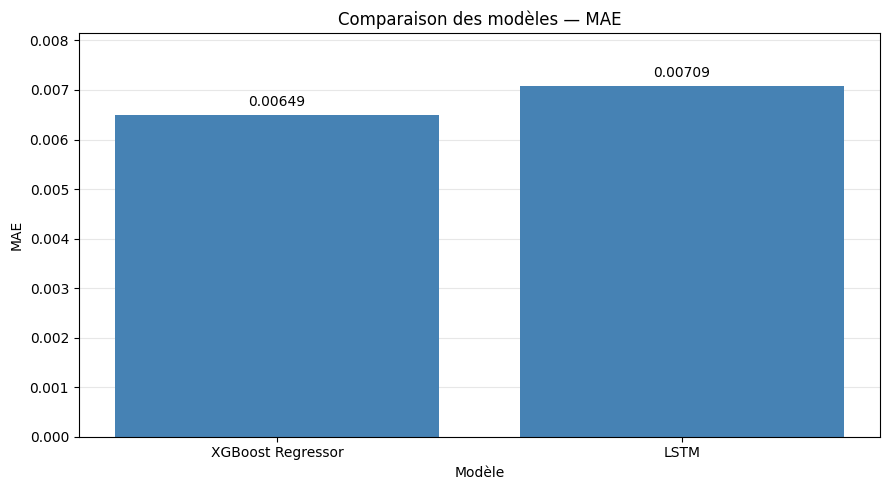

In [ ]:
# Comparer MAE sur un graphique séparé avec les scores non arrondis.
fig, ax = plt.subplots(figsize=(9, 5))
barres = ax.bar(benchmark_classe["model"], benchmark_classe["MAE"], color="steelblue")

# Annoter les valeurs pour faciliter la lecture des petites différences.
ax.bar_label(barres, labels=[f"{valeur:.5f}" for valeur in benchmark_classe["MAE"]], padding=4)
ax.set_title("Comparaison des modèles — MAE")
ax.set_xlabel("Modèle")
ax.set_ylabel("MAE")
ax.axhline(0, color="black", linewidth=0.7)
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


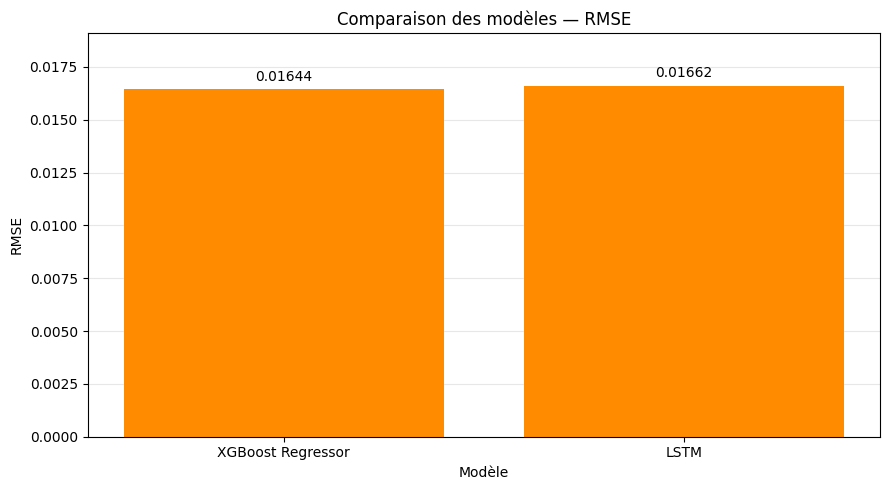

In [ ]:
# Comparer RMSE sur un graphique séparé avec les scores non arrondis.
fig, ax = plt.subplots(figsize=(9, 5))
barres = ax.bar(benchmark_classe["model"], benchmark_classe["RMSE"], color="darkorange")

# Annoter les valeurs pour faciliter la lecture des petites différences.
ax.bar_label(barres, labels=[f"{valeur:.5f}" for valeur in benchmark_classe["RMSE"]], padding=4)
ax.set_title("Comparaison des modèles — RMSE")
ax.set_xlabel("Modèle")
ax.set_ylabel("RMSE")
ax.axhline(0, color="black", linewidth=0.7)
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


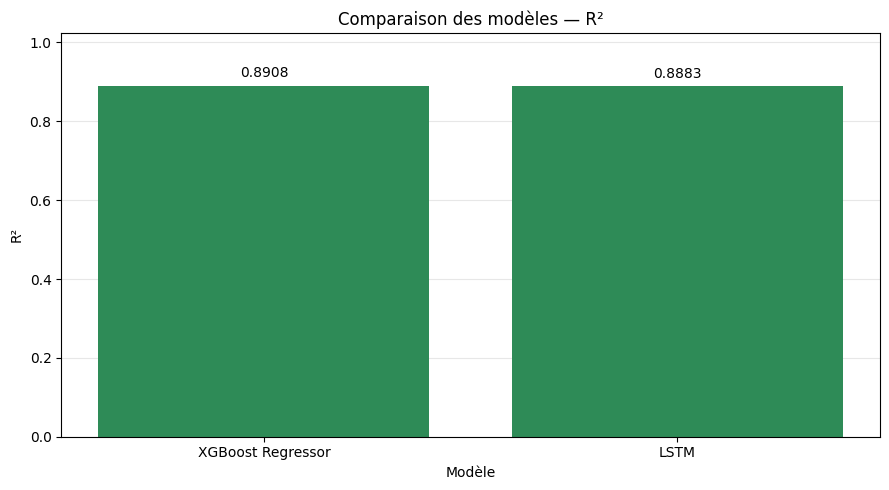

In [ ]:
# Comparer R² sur un graphique séparé avec les scores non arrondis.
fig, ax = plt.subplots(figsize=(9, 5))
barres = ax.bar(benchmark_classe["model"], benchmark_classe["R2"], color="seagreen")

# Annoter les valeurs pour faciliter la lecture des petites différences.
ax.bar_label(barres, labels=[f"{valeur:.4f}" for valeur in benchmark_classe["R2"]], padding=4)
ax.set_title("Comparaison des modèles — R²")
ax.set_xlabel("Modèle")
ax.set_ylabel("R²")
ax.axhline(0, color="black", linewidth=0.7)
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


In [ ]:
# Identifier les meilleurs modèles dans les résultats non arrondis.
rmse_minimale = benchmark_results["RMSE"].min()
r2_maximal = benchmark_results["R2"].max()
meilleurs_rmse = benchmark_results.loc[benchmark_results["RMSE"].eq(rmse_minimale), "model"].tolist()
meilleurs_r2 = benchmark_results.loc[benchmark_results["R2"].eq(r2_maximal), "model"].tolist()
plus_rapide = benchmark_results.loc[benchmark_results["training_time_s"].idxmin()]
plus_lent = benchmark_results.loc[benchmark_results["training_time_s"].idxmax()]

# Générer une interprétation Markdown actualisée à partir des valeurs présentes.
interpretation_benchmark = (
    "### Interprétation des résultats\n\n"
    f"- **Meilleur selon RMSE : {', '.join(meilleurs_rmse)}**, avec {rmse_minimale:.5f}.\n"
    f"- **Meilleur selon R² : {', '.join(meilleurs_r2)}**, avec {r2_maximal:.4f}.\n"
    f"- **Entraînement le plus rapide : {plus_rapide['model']}**, "
    f"avec {plus_rapide['training_time_s']:.3f} s, contre "
    f"{plus_lent['training_time_s']:.3f} s pour {plus_lent['model']}.\n\n"
)

# Décrire le compromis performance-temps sans présupposer le vainqueur.
if plus_rapide["model"] in meilleurs_rmse and plus_rapide["model"] in meilleurs_r2:
    interpretation_benchmark += (
        f"**{plus_rapide['model']} combine ici les meilleurs scores et "
        "le temps d'entraînement le plus court parmi les modèles présents.** "
    )
else:
    interpretation_benchmark += (
        "Le modèle le plus rapide ne domine pas les deux métriques : "
        "le choix dépend du gain de précision et du coût de calcul. "
    )

# Préciser que la recherche complète XGBoost coûte plus que son seul candidat retenu.
ligne_xgboost = benchmark_results.loc[benchmark_results["model"].eq("XGBoost Regressor")]
if not ligne_xgboost.empty and "tuning_time_s" in ligne_xgboost.columns:
    temps_recherche_xgboost = ligne_xgboost.iloc[0]["tuning_time_s"]
    if pd.notna(temps_recherche_xgboost):
        interpretation_benchmark += (
            f"La recherche XGBoost complète a pris {temps_recherche_xgboost:.3f} s, "
            "distinctes du seul entraînement retenu présenté dans le tableau. "
        )
interpretation_benchmark += (
    "Ces conclusions concernent ce test et ces configurations. Les représentations "
    "d'entrée diffèrent entre modèles, et les périmètres des temps d'inférence "
    "restent ceux expliqués dans leurs sections."
)
display(Markdown(interpretation_benchmark))


### Interprétation des résultats

- **Meilleur selon RMSE : XGBoost Regressor**, avec 0.01644.
- **Meilleur selon R² : XGBoost Regressor**, avec 0.8908.
- **Entraînement le plus rapide : XGBoost Regressor**, avec 30.326 s, contre 174.499 s pour LSTM.

**XGBoost Regressor combine ici les meilleurs scores et le temps d'entraînement le plus court parmi les modèles présents.** La recherche XGBoost complète a pris 101.416 s, distinctes du seul entraînement retenu présenté dans le tableau. Ces conclusions concernent ce test et ces configurations. Les représentations d'entrée diffèrent entre modèles, et les périmètres des temps d'inférence restent ceux expliqués dans leurs sections.

### Exports CSV et Excel

Le CSV conserve **toutes les colonnes et les scores non arrondis** de benchmark_results. Le classeur Excel contient une feuille **Benchmark** avec la synthèse classée et une feuille **Résultats complets** avec les données d'origine. Le tableau Markdown est également enregistré pour un rapport. L'export Excel utilise **openpyxl**.


In [ ]:
# Conserver le CSV complet, sans le remplacer par le tableau arrondi.
dossier_resultats.mkdir(parents=True, exist_ok=True)
benchmark_results.to_csv(dossier_resultats / "benchmark_results.csv", index=False)

# Exporter la synthèse et les résultats complets dans deux feuilles Excel.
chemin_excel = dossier_resultats / "benchmark_results.xlsx"
with pd.ExcelWriter(chemin_excel, engine="openpyxl") as writer:
    benchmark_summary.to_excel(writer, sheet_name="Benchmark", index=False)
    benchmark_results.to_excel(writer, sheet_name="Résultats complets", index=False)

    # Figer l'en-tête, activer les filtres et ajuster la largeur des colonnes.
    for feuille in writer.book.worksheets:
        feuille.freeze_panes = "A2"
        feuille.auto_filter.ref = feuille.dimensions
        for colonne in feuille.columns:
            largeur = max(len(str(cellule.value)) if cellule.value is not None else 0 for cellule in colonne)
            feuille.column_dimensions[colonne[0].column_letter].width = min(largeur + 2, 45)

    # Afficher exactement le nombre demandé de décimales dans la synthèse Excel.
    feuille_resume = writer.book["Benchmark"]
    for numero_colonne, nom_colonne in enumerate(benchmark_summary.columns, start=1):
        if nom_colonne in decimales_presentation:
            format_nombre = "0." + "0" * decimales_presentation[nom_colonne]
            for numero_ligne in range(2, len(benchmark_summary) + 2):
                feuille_resume.cell(numero_ligne, numero_colonne).number_format = format_nombre

# Enregistrer le Markdown issu du même DataFrame.
(dossier_resultats / "benchmark_results.md").write_text(
    benchmark_markdown + "\n", encoding="utf-8"
)
print("CSV complet :", dossier_resultats / "benchmark_results.csv")
print("Classeur Excel :", chemin_excel)


CSV complet : C:\Users\User\GoFlow\results\model_benchmark\benchmark_results.csv
Classeur Excel : C:\Users\User\GoFlow\results\model_benchmark\benchmark_results.xlsx


## Benchmark PatchTST — 24 observations, 6 patches

Exécuter **cette section seule** pour poursuivre le benchmark : elle charge les scores sauvegardés et, si nécessaire, réexécute uniquement le notebook 02 de préparation. Aucun entraînement XGBoost ou LSTM n'est déclenché.

**XGBoost** utilise des features tabulaires préparées (lags, moyennes glissantes, calendrier et capteur). **LSTM** traite une séquence par récurrence. **PatchTST** projette des segments temporels en tokens puis utilise l'attention entre patches.

Nous implémentons la variante multivariée simplifiée demandée : chaque token contient **4 temps × 3 variables**, contrairement au traitement indépendant des canaux du [PatchTST original](https://arxiv.org/abs/2211.14730). La fenêtre va de **t−23 à t inclus** : 24 observations représentent 120 minutes d'intervalles, avec 115 minutes entre horodatages extrêmes. La cible reste **target_occupy_t15 = occupy(t+3)**.

Le split et sa purge restent inchangés. Les premières lignes de train sans 24 mesures passées sont exclues des fenêtres, sans padding. Validation et test conservent toutes leurs lignes, dans l'ordre du LSTM. Le passé des périodes précédentes est disponible à l'instant de prévision ; aucune mesure après t n'entre dans une fenêtre.

In [1]:
# Charger les dépendances et les résultats existants sans relancer les anciens modèles.
from pathlib import Path
from time import perf_counter
import copy
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

patch_root = Path.cwd() if Path("data/raw/traffic_dataset.csv").exists() else Path.cwd().parent
dossier_resultats = patch_root / "results/model_benchmark"
patch_saved_results = pd.read_csv(dossier_resultats / "benchmark_results.csv")
# Donner priorité aux scores déjà présents dans le noyau, tout en conservant le CSV.
if "benchmark_results" in globals():
    benchmark_results = pd.concat([patch_saved_results, benchmark_results], ignore_index=True)
    benchmark_results = benchmark_results.drop_duplicates(["model", "target", "horizon_minutes"], keep="last")
else:
    benchmark_results = patch_saved_results.copy()
assert {"XGBoost Regressor", "LSTM"}.issubset(set(benchmark_results["model"]))

# Réutiliser exactement la préparation existante si le noyau ne contient plus le split.
if not all(nom in globals() for nom in ["train", "validation", "test"]):
    get_ipython().run_line_magic("run", str(patch_root / "notebooks/02_feature_engineering.ipynb"))
assert horizon == 3
assert train["timestep"].max() + horizon < validation["timestep"].min()
assert validation["timestep"].max() + horizon < test["timestep"].min()
patch_reference = benchmark_results.loc[
    benchmark_results["model"].eq("LSTM") & benchmark_results["target"].eq("target_occupy_t15")
    & benchmark_results["horizon_minutes"].eq(15)
].iloc[0]
assert [len(train), len(validation), len(test)] == [int(patch_reference[k]) for k in ["n_train", "n_validation", "n_test"]]

patch_seed = 42
torch.manual_seed(patch_seed)
np.random.seed(patch_seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
patch_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if patch_device.type == "cuda":
    torch.cuda.manual_seed_all(patch_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
patch_features = ["flow", "speed", "occupy"]
patch_target = "target_occupy_t15"
patch_sequence_length, patch_length, patch_stride = 24, 4, 4
patch_batch_size, patch_max_epochs, patch_patience = 1024, 20, 4
print("Matériel :", patch_device, "| observations test communes :", len(test))

Shape du dataset source : (3035520, 5)


Nombre de capteurs : 170


Shape avant nettoyage : (3035520, 37)
Shape après nettoyage : (3032970, 37)
Lignes supprimées : 2550
NaN restants par colonne :


timestep                  0
location                  0
flow                      0
occupy                    0
speed                     0
day_index                 0
slot_in_day               0
hour                      0
minute                    0
time_label                0
flow_lag_1                0
flow_lag_2                0
flow_lag_3                0
flow_lag_6                0
flow_lag_12               0
speed_lag_1               0
speed_lag_2               0
speed_lag_3               0
speed_lag_6               0
speed_lag_12              0
occupy_lag_1              0
occupy_lag_2              0
occupy_lag_3              0
occupy_lag_6              0
occupy_lag_12             0
flow_rolling_mean_3       0
flow_rolling_mean_6       0
flow_rolling_mean_12      0
speed_rolling_mean_3      0
speed_rolling_mean_6      0
speed_rolling_mean_12     0
occupy_rolling_mean_3     0
occupy_rolling_mean_6     0
occupy_rolling_mean_12    0
target_flow_t15           0
target_speed_t15    

Timesteps disponibles : 17841
Répartition avant purge : 12488 2676 2677
Début de validation : 12501
Début de test : 15177


Lignes purgées à la fin de train : 510
Lignes purgées à la fin de validation : 510
            Timestep minimum  Timestep maximum  Timesteps distincts  Nombre de lignes  Nombre de capteurs
Ensemble                                                                                                 
Train                     13             12497                12485           2122450                 170
Validation             12501             15173                 2673            454410                 170
Test                   15177             17853                 2677            455090                 170


Matériel : cpu | observations test communes : 455090


### Normalisation et fenêtres indépendantes par capteur

Deux StandardScaler sont ajustés uniquement sur les lignes du **train original** : trois features, puis cible. Les statistiques ne sont jamais recalculées sur validation ou test. Les fenêtres sont assemblées par lots pour limiter la mémoire.

La source est triée par location puis timestep. Des assertions vérifient unicité, continuité et identité du capteur aux deux extrémités de chaque fenêtre. Les indices des fenêtres vont uniquement de t−23 à t. Seules les fenêtres de train peuvent être mélangées entre lots ; leur ordre temporel interne reste intact.

In [2]:
# Ajuster exclusivement sur train, comme pour le LSTM.
patch_scaler_X = StandardScaler().fit(train[patch_features])
patch_scaler_y = StandardScaler().fit(train[[patch_target]])
patch_source = pd.read_csv(patch_root / "data/raw/traffic_dataset.csv", usecols=["location", "timestep"] + patch_features)
patch_source = patch_source.sort_values(["location", "timestep"]).reset_index(drop=True)
assert patch_source["location"].nunique() == 170
assert not patch_source.duplicated(["location", "timestep"]).any()
assert patch_source.groupby("location")["timestep"].diff().dropna().eq(1).all()
assert np.isfinite(patch_source[patch_features].to_numpy()).all()
patch_index = pd.MultiIndex.from_frame(patch_source[["location", "timestep"]])
patch_locations = patch_source["location"].to_numpy()
patch_times = patch_source["timestep"].to_numpy()
patch_base = torch.from_numpy(patch_scaler_X.transform(patch_source[patch_features]).astype("float32"))
patch_offsets = torch.arange(-23, 1)

def indexer_patch(ensemble, autoriser_exclusion=False):
    # Exiger un historique complet du même capteur sans toucher aux frontières du split.
    fins = patch_index.get_indexer(pd.MultiIndex.from_frame(ensemble[["location", "timestep"]]))
    assert (fins >= 0).all()
    debuts = fins - 23
    valides = debuts >= 0
    valides &= patch_locations[np.maximum(debuts, 0)] == ensemble["location"].to_numpy()
    if not autoriser_exclusion:
        assert valides.all(), "Historique incomplet dans validation ou test."
    retenu = ensemble.iloc[np.flatnonzero(valides)]
    fins, debuts = fins[valides], debuts[valides]
    assert np.array_equal(patch_locations[fins], retenu["location"].to_numpy())
    assert np.array_equal(patch_times[fins], retenu["timestep"].to_numpy())
    assert np.all(patch_times[fins] - patch_times[debuts] == 23)
    cibles = patch_scaler_y.transform(retenu[[patch_target]]).ravel().astype("float32")
    return torch.from_numpy(fins.copy()), torch.from_numpy(cibles), retenu

patch_train_ends, patch_y_train, patch_train_rows = indexer_patch(train, True)
patch_val_ends, patch_y_val, patch_val_rows = indexer_patch(validation)
print("Train conservé :", len(patch_train_rows), "| exclu faute d'historique :", len(train) - len(patch_train_rows))
assert tuple(patch_base[patch_train_ends[0] + patch_offsets].shape) == (24, 3)

def lots_patch(fins, cibles=None, melanger=False):
    # Mélanger uniquement les exemples train ; conserver les temps dans chaque fenêtre.
    ordre = torch.randperm(len(fins)) if melanger else torch.arange(len(fins))
    for debut in range(0, len(fins), patch_batch_size):
        selection = ordre[debut:debut + patch_batch_size]
        X = patch_base[fins[selection, None] + patch_offsets].to(patch_device)
        y = None if cibles is None else cibles[selection].to(patch_device)
        yield X, y

def synchroniser_patch():
    # Attendre le GPU avant de lire un chronomètre.
    if patch_device.type == "cuda":
        torch.cuda.synchronize()

Train conservé : 2120580 | exclu faute d'historique : 1870


### Transformer léger et sélection sur validation

Les six patches sont projetés de 12 valeurs vers **64 dimensions**, avec positions apprenables. Deux couches Transformer Encoder utilisent **4 têtes**, un feedforward de **128**, dropout **0,1**, puis pooling moyen et sortie linéaire scalaire. L'attention peut relier tous les patches : ils sont tous antérieurs ou égaux à t, donc aucun masque causal n'est nécessaire pour cette prévision unique.

MSELoss et AdamW (learning rate **0,001**) entraînent uniquement train. Au maximum **20 époques**, patience **4**, meilleur état conservé en mémoire selon la RMSE de validation dans l'échelle originale. Le temps comprend apprentissage et validation ; test n'intervient pas dans cette sélection. Voir la [documentation PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html).

In [3]:
class PatchTST(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(patch_length * 3, 64)
        self.position = nn.Parameter(torch.empty(1, 6, 64))
        nn.init.normal_(self.position, std=0.02)
        couche = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128,
                                           dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        # Initialiser indépendamment les matrices des deux couches clonées.
        for layer in self.encoder.layers:
            for parametre in layer.parameters():
                if parametre.ndim > 1:
                    nn.init.xavier_uniform_(parametre)
        self.sortie = nn.Linear(64, 1)

    def forward(self, X):
        # Chaque patch regroupe quatre temps consécutifs et leurs trois variables.
        patches = X.unfold(1, patch_length, patch_stride).permute(0, 1, 3, 2).reshape(-1, 6, 12)
        tokens = self.projection(patches) + self.position
        return self.sortie(self.encoder(tokens).mean(dim=1)).squeeze(-1)

patch_model = PatchTST().to(patch_device)
patch_optimizer = torch.optim.AdamW(patch_model.parameters(), lr=1e-3, weight_decay=0.01)
patch_loss = nn.MSELoss()
patch_best_rmse, patch_wait = float("inf"), 0
patch_best_state = None
patch_history_rows = []

def rmse_validation_patch():
    # Accumuler la somme des carrés en double précision, sans consulter test.
    patch_model.eval()
    somme = 0.0
    with torch.inference_mode():
        for X, y in lots_patch(patch_val_ends, patch_y_val):
            somme += (patch_model(X).double() - y.double()).square().sum().item()
    return np.sqrt(somme / len(patch_y_val)) * patch_scaler_y.scale_[0]

synchroniser_patch()
patch_training_start = perf_counter()
for epoch in range(1, patch_max_epochs + 1):
    patch_model.train()
    somme_loss = 0.0
    for X, y in lots_patch(patch_train_ends, patch_y_train, melanger=True):
        patch_optimizer.zero_grad(set_to_none=True)
        loss = patch_loss(patch_model(X), y)
        assert torch.isfinite(loss).item(), "Perte non finie."
        loss.backward()
        nn.utils.clip_grad_norm_(patch_model.parameters(), 1.0)
        patch_optimizer.step()
        somme_loss += loss.item() * len(y)
    validation_rmse = rmse_validation_patch()
    assert np.isfinite(validation_rmse)
    patch_history_rows.append({"epoch": epoch,
        "train_RMSE": np.sqrt(somme_loss / len(patch_y_train)) * patch_scaler_y.scale_[0],
        "validation_RMSE": validation_rmse})
    if validation_rmse < patch_best_rmse:
        patch_best_rmse, patch_best_epoch = validation_rmse, epoch
        patch_best_state = copy.deepcopy(patch_model.state_dict())
        patch_wait = 0
    else:
        patch_wait += 1
    print(f"Époque {epoch:02d} : RMSE validation={validation_rmse:.6f}", flush=True)
    if patch_wait >= patch_patience:
        print("Arrêt anticipé sur validation.", flush=True)
        break
assert patch_best_state is not None
patch_model.load_state_dict(patch_best_state)
patch_model.eval()
synchroniser_patch()
patch_training_time_s = perf_counter() - patch_training_start
patch_history = pd.DataFrame(patch_history_rows)
display(patch_history)
print("Meilleure époque :", patch_best_epoch, "| entraînement (s) :", patch_training_time_s)

Époque 01 : RMSE validation=0.015667


Époque 02 : RMSE validation=0.015668


Époque 03 : RMSE validation=0.015614


Époque 04 : RMSE validation=0.015514


Époque 05 : RMSE validation=0.015343


Époque 06 : RMSE validation=0.015383


... (4 outputs left out)

Époque 11 : RMSE validation=0.015405


Arrêt anticipé sur validation.


,epoch,train_RMSE,validation_RMSE
0,1,0.016105,0.015667
1,2,0.015183,0.015668
2,3,0.015062,0.015614
3,4,0.015021,0.015514
4,5,0.014951,0.015343
5,6,0.014946,0.015383
6,7,0.014885,0.015313
7,8,0.014876,0.015466
8,9,0.014849,0.015443
9,10,0.014815,0.015343


Meilleure époque : 7 | entraînement (s) : 2961.9183225000743


### Une seule évaluation finale sur test

Les poids sont maintenant figés. L'échauffement utilise **validation**, puis une seule passe complète produit les prédictions test, réutilisées pour toutes les métriques et figures. Aucune adaptation ne suit les résultats test.

Le temps d'inférence inclut assemblage des fenêtres, transferts éventuels, prédiction et reconversion de la cible. Comme pour LSTM, il exclut chargement et ajustement des scalers. Les observations test sont exactement les mêmes ; les historiques et features des modèles diffèrent.

In [4]:
def predire_patch(fins):
    # Garder l'ordre des lignes et revenir dans l'échelle originale de occupy.
    sorties = []
    with torch.inference_mode():
        for X, _ in lots_patch(fins):
            sorties.append(patch_model(X).cpu().numpy())
    return patch_scaler_y.inverse_transform(np.concatenate(sorties).reshape(-1, 1)).ravel()

patch_test_ends, _, patch_test_rows = indexer_patch(test)
assert patch_test_rows[["location", "timestep"]].equals(test[["location", "timestep"]])
if "lstm_test_ends" in globals():
    assert torch.equal(patch_test_ends, lstm_test_ends)
# Échauffer sur validation pour conserver une seule passe sur test.
_ = predire_patch(patch_val_ends[:patch_batch_size])
synchroniser_patch()
patch_inference_start = perf_counter()
patch_predictions = predire_patch(patch_test_ends)
synchroniser_patch()
patch_inference_time_s = perf_counter() - patch_inference_start
patch_y_test_original = test[patch_target].to_numpy()
assert len(patch_predictions) == len(test) and np.isfinite(patch_predictions).all()
resultat_patch = {
    "model": "PatchTST", "target": patch_target, "horizon_minutes": 15,
    "MAE": mean_absolute_error(patch_y_test_original, patch_predictions),
    "RMSE": float(np.sqrt(mean_squared_error(patch_y_test_original, patch_predictions))),
    "R2": r2_score(patch_y_test_original, patch_predictions),
    "training_time_s": patch_training_time_s, "tuning_time_s": patch_training_time_s,
    "inference_time_s": patch_inference_time_s,
    "inference_us_per_row": patch_inference_time_s / len(test) * 1e6,
    "validation_RMSE": patch_best_rmse, "n_train": len(patch_train_rows),
    "n_validation": len(validation), "n_test": len(test), "n_features": 3,
    "sequence_length": 24, "best_epoch": patch_best_epoch, "epochs_trained": len(patch_history),
    "torch_version": torch.__version__, "device": str(patch_device), "n_jobs": torch.get_num_threads(),
    "hyperparameters": json.dumps({"patch_length": 4, "stride": 4, "d_model": 64,
        "nhead": 4, "num_layers": 2, "dim_feedforward": 128, "dropout": 0.1,
        "learning_rate": 0.001, "batch_size": patch_batch_size, "max_epochs": 20,
        "patience": 4, "weight_decay": 0.01, "variant": "joint_multivariate_patches"}, sort_keys=True),
}
meme_patch = benchmark_results["model"].eq("PatchTST") & benchmark_results["target"].eq(patch_target) & benchmark_results["horizon_minutes"].eq(15)
benchmark_results = pd.concat([benchmark_results.loc[~meme_patch], pd.DataFrame([resultat_patch])], ignore_index=True)
display(pd.DataFrame([resultat_patch])[["model", "MAE", "RMSE", "R2", "n_test"]])

,model,MAE,RMSE,R2,n_test
0,PatchTST,0.007175,0.016646,0.888017,455090


### Graphiques séparés : série temporelle et distribution des erreurs

Le premier capteur est choisi de manière déterministe ; ses 288 premières observations test représentent une journée d'intervalles. L'axe indique le timestep de la **cible t+3**. L'histogramme utilise toutes les erreurs **prédiction − réalité**. Ces diagnostics réutilisent les prédictions déjà calculées.

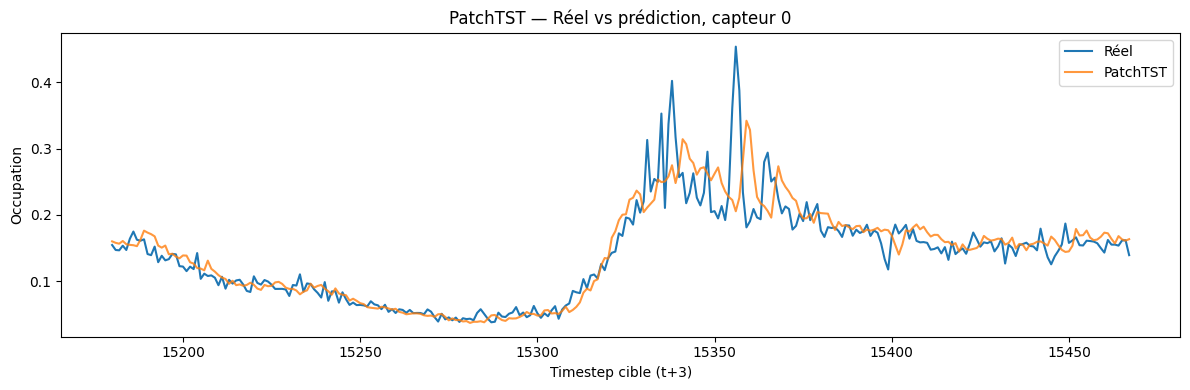

In [5]:
# Choisir un capteur puis trier ses observations pour un échantillon temporel lisible.
patch_plot = test[["location", "timestep"]].copy()
patch_plot["réel"] = patch_y_test_original
patch_plot["prédit"] = patch_predictions
capteur = sorted(test["location"].unique())[0]
extrait = patch_plot.loc[patch_plot["location"].eq(capteur)].sort_values("timestep").head(288)
plt.figure(figsize=(12, 4))
plt.plot(extrait["timestep"] + 3, extrait["réel"], label="Réel")
plt.plot(extrait["timestep"] + 3, extrait["prédit"], label="PatchTST", alpha=0.8)
plt.xlabel("Timestep cible (t+3)")
plt.ylabel("Occupation")
plt.title(f"PatchTST — Réel vs prédiction, capteur {capteur}")
plt.legend()
plt.tight_layout()
plt.show()

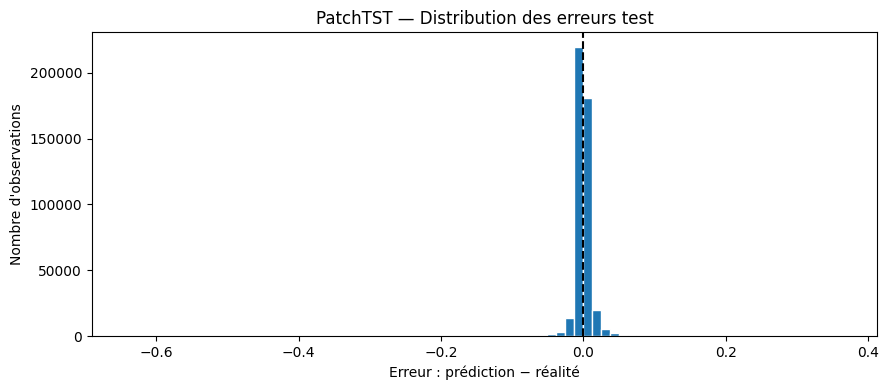

In [6]:
# Décrire toutes les erreurs test sans nouvelle inférence.
plt.figure(figsize=(9, 4))
plt.hist(patch_predictions - patch_y_test_original, bins=80, edgecolor="white")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Erreur : prédiction − réalité")
plt.ylabel("Nombre d'observations")
plt.title("PatchTST — Distribution des erreurs test")
plt.tight_layout()
plt.show()

### Tableau comparatif et sauvegarde

Le rang et le tri utilisent la RMSE non arrondie, pour la même cible et le même horizon. Le CSV garde tous les champs ; si le classeur Excel existe, ses feuilles Benchmark et Résultats complets sont actualisées en conservant les autres feuilles. Les temps restent dépendants du matériel et du périmètre d'inférence propre à chaque modèle.

In [7]:
# Construire le tableau sur la tâche commune, avec les scores réellement mesurés.
patch_comparison = benchmark_results.loc[benchmark_results["target"].eq(patch_target) & benchmark_results["horizon_minutes"].eq(15)].sort_values("RMSE", kind="stable").reset_index(drop=True)
patch_columns = {"model": "Model", "target": "Target", "horizon_minutes": "Horizon (min)",
    "MAE": "MAE", "RMSE": "RMSE", "R2": "R²", "training_time_s": "Training Time (s)",
    "inference_time_s": "Inference Time (s)"}
patch_summary = patch_comparison[list(patch_columns)].rename(columns=patch_columns)
patch_summary.insert(0, "Rank", patch_comparison["RMSE"].rank(method="min").astype(int))
display(patch_summary.style.format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R²": "{:.4f}",
    "Training Time (s)": "{:.3f}", "Inference Time (s)": "{:.3f}"}))

# Enregistrer uniquement après entraînement et évaluation réels.
benchmark_results.to_csv(dossier_resultats / "benchmark_results.csv", index=False)
chemin_excel = dossier_resultats / "benchmark_results.xlsx"
if chemin_excel.exists():
    with pd.ExcelWriter(chemin_excel, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        patch_summary.to_excel(writer, sheet_name="Benchmark", index=False)
        benchmark_results.to_excel(writer, sheet_name="Résultats complets", index=False)
patch_history.to_csv(dossier_resultats / "patchtst_training_history.csv", index=False)
torch.save({"state_dict": {nom: poids.cpu() for nom, poids in patch_best_state.items()},
    "feature_names": patch_features, "sequence_length": 24,
    "hyperparameters": json.loads(resultat_patch["hyperparameters"]),
    "feature_mean": patch_scaler_X.mean_.tolist(), "feature_scale": patch_scaler_X.scale_.tolist(),
    "target_mean": patch_scaler_y.mean_.tolist(), "target_scale": patch_scaler_y.scale_.tolist(),
    "best_epoch": patch_best_epoch}, dossier_resultats / "patchtst_best.pt")
print("Résultats sauvegardés :", dossier_resultats)

,Rank,Model,Target,Horizon (min),MAE,RMSE,R²,Training Time (s),Inference Time (s)
0,1,XGBoost Regressor,target_occupy_t15,15,0.00649,0.01644,0.8908,30.326,0.465
1,2,LSTM,target_occupy_t15,15,0.00709,0.01662,0.8883,174.499,0.764
2,3,PatchTST,target_occupy_t15,15,0.00717,0.01665,0.8880,2961.918,8.773


Résultats sauvegardés : C:\Users\User\GoFlow\results\model_benchmark


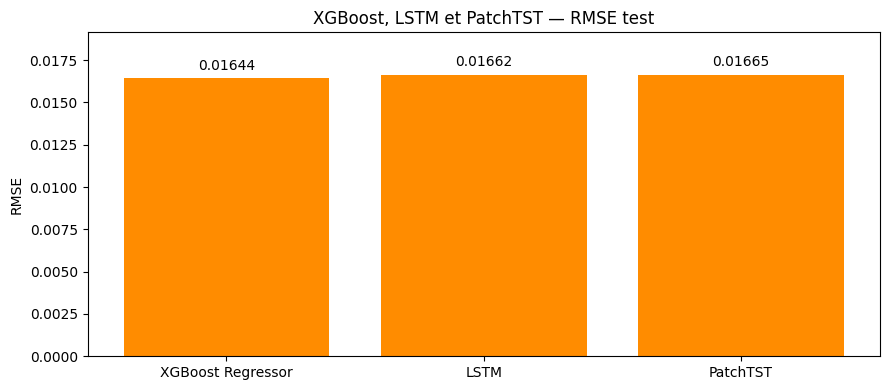

In [8]:
# Comparer les RMSE sur une figure indépendante.
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.bar(patch_comparison["model"], patch_comparison["RMSE"], color="darkorange")
ax.bar_label(barres, fmt="%.5f", padding=4)
ax.set_ylabel("RMSE")
ax.set_title("XGBoost, LSTM et PatchTST — RMSE test")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

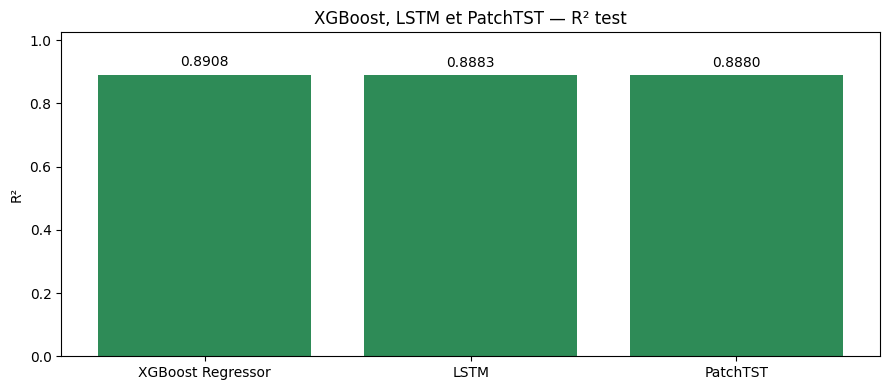

In [9]:
# Comparer les R² sur une figure indépendante, avec zéro comme référence.
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.bar(patch_comparison["model"], patch_comparison["R2"], color="seagreen")
ax.bar_label(barres, fmt="%.4f", padding=4)
ax.axhline(0, color="black", linewidth=0.7)
ax.set_ylabel("R²")
ax.set_title("XGBoost, LSTM et PatchTST — R² test")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

### Conclusion automatique

La conclusion ci-dessous est calculée uniquement à partir des scores non arrondis sauvegardés. Elle décrit la précision et les temps mesurés, sans sélectionner une nouvelle configuration à partir du test.

In [10]:
# Identifier les gagnants, y compris les éventuelles égalités exactes.
rmse_min = patch_comparison["RMSE"].min()
r2_max = patch_comparison["R2"].max()
gagnants_rmse = ", ".join(patch_comparison.loc[patch_comparison["RMSE"].eq(rmse_min), "model"])
gagnants_r2 = ", ".join(patch_comparison.loc[patch_comparison["R2"].eq(r2_max), "model"])
rapide_train = patch_comparison.loc[patch_comparison["training_time_s"].idxmin()]
rapide_inference = patch_comparison.loc[patch_comparison["inference_time_s"].idxmin()]
display(Markdown(
    f"**Meilleur selon RMSE : {gagnants_rmse}** ({rmse_min:.5f}). "
    f"**Meilleur selon R² : {gagnants_r2}** ({r2_max:.4f}).\n\n"
    f"Compromis performance / temps : l'entraînement le plus court est celui de **{rapide_train['model']}** "
    f"({rapide_train['training_time_s']:.3f} s), avec une RMSE de {rapide_train['RMSE']:.5f} ; "
    f"l'inférence la plus courte est celle de **{rapide_inference['model']}** "
    f"({rapide_inference['inference_time_s']:.3f} s). "
    "Comparer le gain de précision aux coûts du tableau ; les temps d'inférence couvrent des préparations différentes. "
    "XGBoost dispose de features supplémentaires et PatchTST d'un historique plus long que LSTM."
))

**Meilleur selon RMSE : XGBoost Regressor** (0.01644). **Meilleur selon R² : XGBoost Regressor** (0.8908).

Compromis performance / temps : l'entraînement le plus court est celui de **XGBoost Regressor** (30.326 s), avec une RMSE de 0.01644 ; l'inférence la plus courte est celle de **XGBoost Regressor** (0.465 s). Comparer le gain de précision aux coûts du tableau ; les temps d'inférence couvrent des préparations différentes. XGBoost dispose de features supplémentaires et PatchTST d'un historique plus long que LSTM.